<img src=https://courseware.decoded.com/images/decoded/logo-decoded.png align=left width=100px/>

# Exploratory Data Analysis
---
<small>© COPYRIGHT 2026 DECODED LIMITED. ALL RIGHTS RESERVED. Web: https://decoded.com/ </small>

## Programmes

* Data science accelerator - Exploratory Data Analysis

## Content

## Purpose

In this notebook, we will use exploratory data analysis, or EDA, to understand a university performance dataset.

The goal is not to build a predictive model yet. The goal is to ask better questions, check data quality, summarise patterns, and prepare a clear data story.

We will use **two datasets throughout**:

1. `university_performance.csv` — one row per student.
2. `university_support_lookup.csv` — one row per programme, with school and target information.

Using the same scenario throughout helps you focus on the concepts rather than constantly learning new contexts.


---

### Why study EDA?


Being skillful in exploratory data analysis is crucial for any data analysis project as it helps you to better understand your data, make informed decisions about how to analyze it, and communicate your insights effectively to others.

For example, by exploring your data visually and statistically, you can gain insights into the underlying structure of the data and make informed decisions about how to model and analyze it. By creating effective visualizations and summaries of your data, you can convey your findings in a clear and concise manner.

### Why does a professional data wrangling pipeline matter?

Raw data is rarely ready for analysis. A professional pipeline transforms messy data into reliable insights. Here's why it matters:

**Efficiency & Scalability**
- Process 500 rows or 5 million rows with the **same code**
- Avoid repetitive manual steps that waste time and introduce errors
- Automate transformations so you focus on analysis, not data cleaning

**Reliability & Consistency**
- Clear, linear flow prevents confusion and mistakes
- Same pipeline produces same results every time (reproducibility)
- Easy to debug: if something breaks, you know exactly which step failed

**Professional Communication**
- A well-structured pipeline tells a story: "Here's what we did to the raw data"
- Colleagues and future-you can understand the logic at a glance
- Confidence in your analysis because the pipeline is transparent and auditable

**Memory Efficiency**
- Avoid creating 5+ copies of your dataset in RAM
- Chaining operations keeps memory usage minimal
- Critical for large datasets (millions of rows)

**Maintainability & Collaboration**
- When requirements change, update the pipeline once—not scattered across 10 cells
- New team members can read and modify the code without breaking it
- Safer handoffs: clear structure prevents accidental side effects


## Learning outcomes

By the end of this part, you will be able to:

- load CSV files into pandas DataFrames
- inspect the shape, columns, and first rows of a dataset
- clean text and missing values in beginner-friendly steps
- use method chaining to make cleaning steps easier to read
- use `groupby()` to summarise data by category
- use `merge()` to join two related datasets
- explore correlations between numeric columns
- create simple charts to support an insight
- turn EDA findings into a short data story


## Scenario

You work in the analytics team at a university.

The university wants to understand student engagement and performance across programmes. You have two datasets:

| Dataset | What it contains | How we use it |
|---|---|---|
| `university_performance.csv` | Student-level data: attendance, engagement, submissions, scores and risk band | Main EDA dataset |
| `university_support_lookup.csv` | Programme-level lookup data: school, programme lead and targets | Extra context to join onto the main dataset |

This notebook keeps to these two datasets throughout so the learning flow is easier to follow.


## 1. Import the libraries

A **library** is a collection of code written by other people. We import libraries so that we can use their tools.

In this notebook:

- `pandas` helps us work with tables of data
- `numpy` helps with numeric operations
- `matplotlib.pyplot` helps us create simple charts

The word after `as` is a shorter nickname. For example, `pd` is the common nickname for `pandas`.


In [1]:
# Import the libraries we need.
# Run this cell first.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## 2. Load the two CSV files

A CSV file is a plain text file that stores data in rows and columns.

`pd.read_csv()` reads a CSV file and turns it into a pandas DataFrame. A **DataFrame** is like a spreadsheet inside Python.


In [2]:
# Load the main student-level dataset.
# The file must be in the same folder as this notebook.

performance_df = pd.read_csv("university_performance.csv")
#performance_df = pd.read_csv("/content/university_performance.csv")

# Load the programme lookup dataset.
lookup_df = pd.read_csv("university_support_lookup.csv")
#lookup_df = pd.read_csv("/content/university_support_lookup.csv")


## 3. Preview each dataset

Before analysing data, always check that it has loaded correctly.

`.head()` shows the first five rows. This helps us spot obvious issues early.


In [3]:
# Preview the main dataset.
performance_df.head()


,University_ID,Applications,Accepted,Enrolled,Spend_Per_Student,Spend_Band_Hint,Student_Satisfaction,Research_Score,Staff_Student_Ratio,Private,...,Data_Policy,Graduation_Rate,Strong_Outcome,programme,attendance_rate,engagement_score,submission_rate,Regional_Advisor,Support_Priority,Annual_Support_Budget
0,UNI0001,2874,1707,1273,27111.67,Upper,74.4,65.4,12.4,No,...,UNI_2026,75.0,1,data science,71.1,62.5,67.6,Ben,Medium,90000
1,UNI0002,17253,10971,3729,17358.64,Middle,74.7,60.1,10.4,No,...,UNI_2026,67.9,0,MECHANICAL ENGINEERING,56.2,58.2,59.8,Ben,Medium,90000
2,UNI0003,14746,4041,1368,21362.45,Middle,60.6,66.0,11.1,No,...,UNI_2026,67.6,0,artificial intelligence,60.5,46.2,53.3,Chloe,Medium,98000
3,UNI0004,10216,4966,1608,4500.00,Lower,67.2,55.2,15.2,No,...,UNI_2026,57.9,0,MECHANICAL ENGINEERING,52.8,45.0,49.5,Daniel,Low,82000
4,UNI0005,10093,2489,1516,11483.74,Lower,86.4,84.2,6.7,Yes,...,UNI_2026,84.7,1,ARTIFICIAL INTELLIGENCE,67.7,85.6,73.1,Ben,Medium,90000


In [4]:
# Preview the lookup dataset.
lookup_df.head()


,Region,Regional_Advisor,Support_Priority,Annual_Support_Budget,Target_Engagement_Score,Target_Student_Satisfaction
0,North,Amina,High,125000,69.0,70.0
1,South,Ben,Medium,90000,66.0,67.0
2,East,Chloe,Medium,98000,65.0,68.0
3,West,Daniel,Low,82000,64.0,66.0


## 4. Check the size of the data

`.shape` tells us the number of rows and columns.

It returns two numbers:

- rows first
- columns second


In [5]:
# Check rows and columns in the main dataset.
performance_df.shape


(240, 23)

In [6]:
# Check rows and columns in the lookup dataset.
lookup_df.shape


(4, 6)

## 5. Check the column names

Column names matter because we use them in our code.

This dataset already uses mostly clean names, but it still helps to inspect them before writing analysis code.


In [7]:
# List all column names in the main dataset.
performance_df.columns


Index(['University_ID', ' Applications ', 'Accepted', 'Enrolled',
       'Spend_Per_Student', 'Spend_Band_Hint', 'Student_Satisfaction',
       'Research_Score', 'Staff_Student_Ratio', 'Private', 'Region',
       'Campus Type ', 'Funding_Band', 'Data_Policy', 'Graduation_Rate',
       'Strong_Outcome', 'programme', 'attendance_rate', 'engagement_score',
       'submission_rate', 'Regional_Advisor', 'Support_Priority',
       'Annual_Support_Budget'],
      dtype='object')

## 6. Check data types and missing values

`.info()` gives us a quick technical summary.

Look for:

- column names
- data types, such as `object`, `int64` and `float64`
- non-null counts, which help us spot missing values


In [8]:
# Check data types and missing values.
performance_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   University_ID          240 non-null    object 
 1    Applications          240 non-null    int64  
 2   Accepted               240 non-null    int64  
 3   Enrolled               240 non-null    int64  
 4   Spend_Per_Student      240 non-null    float64
 5   Spend_Band_Hint        240 non-null    object 
 6   Student_Satisfaction   240 non-null    float64
 7   Research_Score         240 non-null    float64
 8   Staff_Student_Ratio    240 non-null    float64
 9   Private                240 non-null    object 
 10  Region                 240 non-null    object 
 11  Campus Type            240 non-null    object 
 12  Funding_Band           240 non-null    object 
 13  Data_Policy            240 non-null    object 
 14  Graduation_Rate        240 non-null    float64
 15  Strong

## 7. Count missing values

Missing values are blank or unknown values.

`.isna()` checks each cell and returns `True` where a value is missing.

`.sum()` then counts how many missing values each column has.


In [9]:
# Count missing values in each column.
performance_df.isna().sum()


University_ID            0
 Applications            0
Accepted                 0
Enrolled                 0
Spend_Per_Student        0
Spend_Band_Hint          0
Student_Satisfaction     0
Research_Score           0
Staff_Student_Ratio      0
Private                  0
Region                   0
Campus Type              0
Funding_Band             0
Data_Policy              0
Graduation_Rate          0
Strong_Outcome           0
programme                0
attendance_rate          0
engagement_score         0
submission_rate          0
Regional_Advisor         0
Support_Priority         0
Annual_Support_Budget    0
dtype: int64

## 8. Clean text columns step by step

Some text values may contain extra spaces or inconsistent capitalisation.

For example, `" COMPUTER SCIENCE "` and `"Computer Science"` should mean the same thing.

We will clean:

- `programme`
- `region`

The pattern is:

1. select a column
2. use `.str.strip()` to remove spaces from the start and end
3. use `.str.title()` or `.str.upper()` to standardise capitalisation


In [10]:

# Make a copy so we keep the original data unchanged.
clean_df = performance_df.copy()
clean_lookup = lookup_df.copy()

clean_df.columns = clean_df.columns.str.strip().str.lower().str.replace(" ", "_")

clean_lookup.columns = clean_lookup.columns.str.strip().str.lower().str.replace(" ", "_")

# Clean the programme column.
clean_df["programme"] = clean_df["programme"].str.strip().str.title()

# Clean the region column.
# We use lower case because region values are short labels: North, East, South, West.
clean_df["region"] = clean_df["region"].str.strip()

# Preview the cleaned columns.
clean_df[["programme", "region"]].head()


,programme,region
0,Data Science,South
1,Mechanical Engineering,South
2,Artificial Intelligence,East
3,Mechanical Engineering,West
4,Artificial Intelligence,South


## 9. Fill missing numeric values

For this teaching dataset, missing values are small in number.

We will use the **median** to fill missing values in numeric columns. The median is the middle value. It is often safer than the mean when there are outliers.

We will fill missing values in:

- `attendance_rate`
- `engagement_score`
- `submission_rate`


In [11]:
performance_df.columns

Index(['University_ID', ' Applications ', 'Accepted', 'Enrolled',
       'Spend_Per_Student', 'Spend_Band_Hint', 'Student_Satisfaction',
       'Research_Score', 'Staff_Student_Ratio', 'Private', 'Region',
       'Campus Type ', 'Funding_Band', 'Data_Policy', 'Graduation_Rate',
       'Strong_Outcome', 'programme', 'attendance_rate', 'engagement_score',
       'submission_rate', 'Regional_Advisor', 'Support_Priority',
       'Annual_Support_Budget'],
      dtype='object')

In [12]:

# Choose the columns we want to fill.
numeric_columns_to_fill = ["attendance_rate", "engagement_score", "submission_rate"]

# Loop through each column and fill missing values with that column's median.
for column in numeric_columns_to_fill:
    median_value = clean_df[column].median()
    clean_df[column] = clean_df[column].fillna(median_value)

# Check missing values again.
clean_df[numeric_columns_to_fill].isna().sum()


attendance_rate     0
engagement_score    0
submission_rate     0
dtype: int64

## 10. Create a simple calculated column

A calculated column is a new column made from existing columns.

Here we create an `engagement_gap` column. It shows how far each learner is from an engagement score of 70.

A positive value means the student is above 70. A negative value means the student is below 70.


In [13]:
# Create a new column.
clean_df["engagement_gap"] = clean_df["engagement_score"] - 70

# Preview the new column with the original engagement score.
clean_df[["university_id", "engagement_score", "engagement_gap"]].head()


,university_id,engagement_score,engagement_gap
0,UNI0001,62.5,-7.5
1,UNI0002,58.2,-11.8
2,UNI0003,46.2,-23.8
3,UNI0004,45.0,-25.0
4,UNI0005,85.6,15.6


## 11. Method chaining: the same cleaning in a cleaner flow

A method chain is when we connect several pandas steps together.

This can make code easier to read because each line is one step in the pipeline.

Do not worry if this feels new. Read it from top to bottom.


In [14]:
# This method chain repeats the key cleaning steps in one clear pipeline.
# The backslash is not needed because the code is inside brackets.

analysis_df = (
    clean_df
    .copy()
    .assign(
        programme=lambda df: df["programme"].str.strip().str.title(),
        region=lambda df: df["region"].str.strip(),
        attendance_rate=lambda df: df["attendance_rate"].fillna(df["attendance_rate"].median()),
        engagement_score=lambda df: df["engagement_score"].fillna(df["engagement_score"].median()),
        submission_rate=lambda df: df["submission_rate"].fillna(df["submission_rate"].median()),
    )
    .assign(
        engagement_gap=lambda df: df["engagement_score"] - 70
    )
)

analysis_df.head()


,university_id,applications,accepted,enrolled,spend_per_student,spend_band_hint,student_satisfaction,research_score,staff_student_ratio,private,...,graduation_rate,strong_outcome,programme,attendance_rate,engagement_score,submission_rate,regional_advisor,support_priority,annual_support_budget,engagement_gap
0,UNI0001,2874,1707,1273,27111.67,Upper,74.4,65.4,12.4,No,...,75.0,1,Data Science,71.1,62.5,67.6,Ben,Medium,90000,-7.5
1,UNI0002,17253,10971,3729,17358.64,Middle,74.7,60.1,10.4,No,...,67.9,0,Mechanical Engineering,56.2,58.2,59.8,Ben,Medium,90000,-11.8
2,UNI0003,14746,4041,1368,21362.45,Middle,60.6,66.0,11.1,No,...,67.6,0,Artificial Intelligence,60.5,46.2,53.3,Chloe,Medium,98000,-23.8
3,UNI0004,10216,4966,1608,4500.00,Lower,67.2,55.2,15.2,No,...,57.9,0,Mechanical Engineering,52.8,45.0,49.5,Daniel,Low,82000,-25.0
4,UNI0005,10093,2489,1516,11483.74,Lower,86.4,84.2,6.7,Yes,...,84.7,1,Artificial Intelligence,67.7,85.6,73.1,Ben,Medium,90000,15.6


## 12. Quick quality checks

After cleaning, run a few checks.

These checks help us confirm that our dataset is ready for analysis.


In [15]:
# Check that there are no missing values in the columns we cleaned.
analysis_df[["programme", "region", "attendance_rate", "engagement_score", "submission_rate"]].isna().sum()


programme           0
region              0
attendance_rate     0
engagement_score    0
submission_rate     0
dtype: int64

#### What are your findings?

In [16]:
# Check the unique programme names.
# This helps us confirm that messy versions have been standardised.
analysis_df["programme"].sort_values().unique()


array(['Artificial Intelligence', 'Business Management',
       'Computer Science', 'Cyber Security', 'Data Science', 'Economics',
       'Mechanical Engineering', 'Psychology'], dtype=object)

## 13. Descriptive statistics

`.describe()` gives summary statistics for numeric columns.

Look for:

- mean: the average
- min and max: the range
- 25%, 50%, 75%: quartiles, which show the spread of the data


In [17]:
# Show descriptive statistics for numeric columns.
analysis_df.describe()


,applications,accepted,enrolled,spend_per_student,student_satisfaction,research_score,staff_student_ratio,graduation_rate,strong_outcome,attendance_rate,engagement_score,submission_rate,annual_support_budget,engagement_gap
count,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000
mean,11715.816667,6345.883333,3333.104167,18639.818417,71.742917,57.962917,14.960833,69.517083,0.366667,59.964167,58.259583,57.375833,99637.500000,-11.740417
std,5706.941613,3992.762637,2396.112155,6548.170336,9.951079,18.103374,4.236162,9.282291,0.482902,9.285173,9.320935,9.173525,16769.101704,9.320935
min,1154.000000,421.000000,175.000000,4500.000000,35.500000,10.300000,6.000000,39.400000,0.000000,45.000000,40.000000,45.000000,82000.000000,-30.000000
25%,7017.750000,3212.250000,1566.500000,13608.937500,66.100000,46.275000,12.250000,63.625000,0.000000,53.025000,51.600000,49.900000,88000.000000,-18.400000
50%,11480.000000,5681.500000,2841.500000,18898.570000,72.300000,57.900000,15.050000,68.700000,0.000000,59.250000,58.100000,55.850000,98000.000000,-11.900000
75%,16709.750000,8834.250000,4389.750000,23079.765000,77.675000,70.025000,17.650000,75.225000,1.000000,67.350000,63.350000,65.450000,125000.000000,-6.650000
max,21918.000000,17682.000000,11520.000000,35570.630000,98.000000,100.000000,25.800000,91.600000,1.000000,90.200000,85.600000,81.900000,125000.000000,15.600000


## 14. Group by one category

`groupby()` lets us summarise data by a category.

Here, we calculate average attendance and engagement score for each programme.


In [18]:
# Group by programme and calculate averages.
programme_summary = (
    analysis_df
    .groupby("programme")
    [["attendance_rate", "engagement_score"]]
    .mean()
    .round(1)
)

programme_summary


,attendance_rate,engagement_score
programme,,
Artificial Intelligence,60.7,59.5
Business Management,60.4,58.5
Computer Science,59.2,57.8
Cyber Security,60.7,58.5
Data Science,59.2,57.2
Economics,59.6,60.0
Mechanical Engineering,60.5,58.0
Psychology,59.1,56.7


## 15. Group by two categories

We can also group by more than one column.

Here, we compare average assessment score by programme and region.


In [19]:
# Group by programme and year of study.
programme_year_summary = (
    analysis_df
    .groupby(["programme", "region"])
    ["engagement_score"]
    .mean()
    .round(1)
    .reset_index()
)

programme_year_summary.head(12)


,programme,region,engagement_score
0,Artificial Intelligence,East,56.3
1,Artificial Intelligence,North,63.1
2,Artificial Intelligence,South,61.7
3,Artificial Intelligence,West,55.0
4,Business Management,East,57.6
5,Business Management,North,61.2
6,Business Management,South,56.2
7,Business Management,West,57.6
8,Computer Science,East,55.4
9,Computer Science,North,59.5


## 16. Join the lookup dataset

The lookup dataset contains programme-level information, such as school and programme lead.

We use `merge()` to join this information onto the university-level dataset.

The shared column is `region`.


In [20]:
# Join the two datasets.
# how="left" means: keep every row from analysis_df and add matching data from lookup_df.



enriched_df = analysis_df.merge(
    clean_lookup,
    on="region",
    how="left"
)

enriched_df.head()


,university_id,applications,accepted,enrolled,spend_per_student,spend_band_hint,student_satisfaction,research_score,staff_student_ratio,private,...,submission_rate,regional_advisor_x,support_priority_x,annual_support_budget_x,engagement_gap,regional_advisor_y,support_priority_y,annual_support_budget_y,target_engagement_score,target_student_satisfaction
0,UNI0001,2874,1707,1273,27111.67,Upper,74.4,65.4,12.4,No,...,67.6,Ben,Medium,90000,-7.5,Ben,Medium,90000,66.0,67.0
1,UNI0002,17253,10971,3729,17358.64,Middle,74.7,60.1,10.4,No,...,59.8,Ben,Medium,90000,-11.8,Ben,Medium,90000,66.0,67.0
2,UNI0003,14746,4041,1368,21362.45,Middle,60.6,66.0,11.1,No,...,53.3,Chloe,Medium,98000,-23.8,Chloe,Medium,98000,65.0,68.0
3,UNI0004,10216,4966,1608,4500.00,Lower,67.2,55.2,15.2,No,...,49.5,Daniel,Low,82000,-25.0,Daniel,Low,82000,64.0,66.0
4,UNI0005,10093,2489,1516,11483.74,Lower,86.4,84.2,6.7,Yes,...,73.1,Ben,Medium,90000,15.6,Ben,Medium,90000,66.0,67.0


## 17. Check the join worked

After a join, check whether any lookup fields are missing.

If `region` is missing, it might mean the programme name did not match between the two datasets.


In [21]:
# Count missing values in the new lookup columns.
enriched_df[["region", "applications", "private", "regional_advisor_x"]].isna().sum()


region                0
applications          0
private               0
regional_advisor_x    0
dtype: int64

## 18. Compare actual performance with targets

Now that target columns are joined, we can create simple gap columns.

A gap column helps us compare actual values with expected values.


In [23]:
# Create target gap columns.
enriched_df["student_satisfaction_target_gap"] = enriched_df["student_satisfaction"] - enriched_df["target_student_satisfaction"]
enriched_df["engagement_target_gap"] = enriched_df["engagement_score"] - enriched_df["target_engagement_score"]

enriched_df[["programme", "engagement_target_gap","student_satisfaction_target_gap"]]

,programme,engagement_target_gap,student_satisfaction_target_gap
0,Data Science,-3.5,7.4
1,Mechanical Engineering,-7.8,7.7
2,Artificial Intelligence,-18.8,-7.4
3,Mechanical Engineering,-19.0,1.2
4,Artificial Intelligence,19.6,19.4
...,...,...,...
235,Business Management,-9.1,6.1
236,Data Science,3.6,30.5
237,Data Science,-26.0,-8.8
238,Artificial Intelligence,7.0,19.7


## 19. Summarise by region

Because we joined the lookup table, we can now analyse at regional level.

This is useful when leaders need a higher-level view.


In [26]:
# Summarise performance by school.
school_summary = (
    enriched_df
    .groupby("region")
    .agg(
        universities=("university_id", "count"),
        average_satisfaction=("student_satisfaction_target_gap", "mean"),
        average_engagement=("engagement_target_gap", "mean"),
    )
    .round(1)
    .reset_index()
)

school_summary


,region,universities,average_satisfaction,average_engagement
0,East,56,4.2,-7.9
1,North,67,2.8,-8.1
2,South,57,4.5,-7.8
3,West,60,4.3,-7.6


## 20. Correlation

Correlation helps us understand whether two numeric columns move together.

A correlation close to `1` means they tend to increase together.

A correlation close to `-1` means one tends to increase as the other decreases.

A correlation close to `0` means there is no clear straight-line relationship.


In [27]:
# Select numeric columns for correlation.
numeric_for_correlation = [
    "spend_per_student",
    "engagement_score",
    "submission_rate",
    "staff_student_ratio",
    "research_score",
    "student_satisfaction"
]

correlation_table = enriched_df[numeric_for_correlation].corr().round(2)
correlation_table


,spend_per_student,engagement_score,submission_rate,staff_student_ratio,research_score,student_satisfaction
spend_per_student,1.00,0.22,0.40,-0.12,-0.01,-0.02
engagement_score,0.22,1.00,0.75,-0.37,0.32,0.61
submission_rate,0.40,0.75,1.00,-0.37,0.26,0.40
staff_student_ratio,-0.12,-0.37,-0.37,1.00,0.02,-0.07
research_score,-0.01,0.32,0.26,0.02,1.00,0.01
student_satisfaction,-0.02,0.61,0.40,-0.07,0.01,1.00


## 21. Visualise a relationship

A scatter plot helps us see the relationship between two numeric columns.

Each dot is one student.


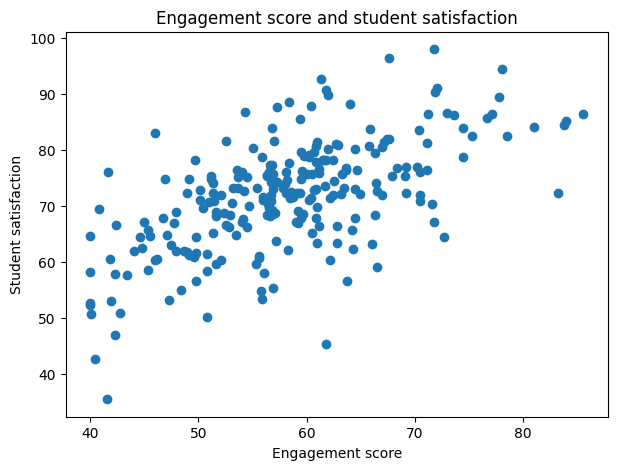

In [28]:
# Create a scatter plot of engagement score and assessment score.
plt.figure(figsize=(7, 5))
plt.scatter(enriched_df["engagement_score"], enriched_df["student_satisfaction"])
plt.title("Engagement score and student satisfaction")
plt.xlabel("Engagement score")
plt.ylabel("Student satisfaction")
plt.show()


## 22. Visualise a grouped summary

A bar chart is useful when comparing categories.

Here, we compare average engagement score by programme.


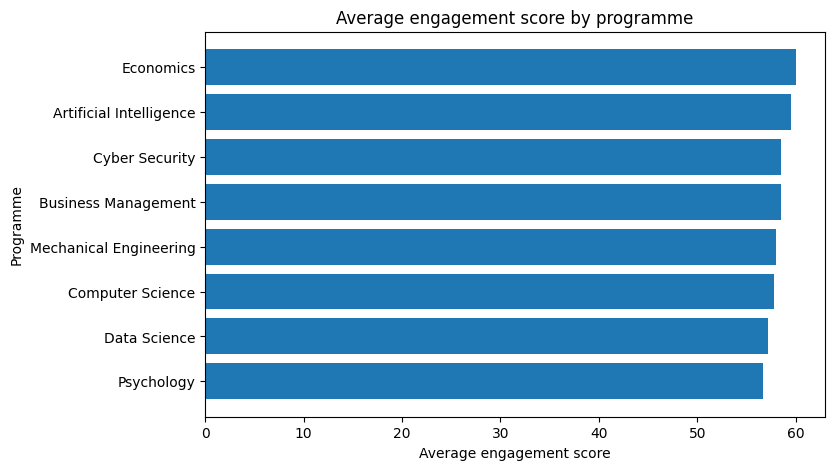

In [30]:
# Sort programmes by average assessment score so the chart is easier to read.
programme_chart_data = programme_summary.sort_values("engagement_score")

plt.figure(figsize=(8, 5))
plt.barh(programme_chart_data.index, programme_chart_data["engagement_score"])
plt.title("Average engagement score by programme")
plt.xlabel("Average engagement score")
plt.ylabel("Programme")
plt.show()


## 23. Learner reflection

Use the outputs above to complete this reflection.

- What is one data quality issue you found?
- Which programme or school would you investigate first?
- Which chart best supports your recommendation?
- What extra data would help you make a better decision?

Write two or three sentences in your own words.


In [ ]:
# Optional: write your short data story as a Python string.
# This cell is here for practice. You can edit the text between the triple quotes.

my_data_story = """
Observation:

Evidence:

Interpretation:

Action:
"""

print(my_data_story)


## 24. End-of-notebook checks

These small checks help confirm that the notebook has run correctly.


In [ ]:
# These checks should all pass if the notebook has run correctly.
assert len(performance_df) > 0
assert len(lookup_df) > 0
assert "school" in enriched_df.columns
assert enriched_df["programme"].nunique() == lookup_df["programme"].nunique()
assert enriched_df["assessment_score"].between(0, 100).all()

print("All checks passed. The EDA notebook ran successfully.")


## Summary

You have used one university scenario and two related datasets to practise the core EDA workflow:

- load data
- inspect structure
- clean text and missing values
- create calculated columns
- use method chaining
- group and aggregate
- join a lookup table
- explore relationships
- visualise findings
- shape a short data story

In the next module, this same university scenario can be used to prepare data for modelling.
